In [6]:
# ==============================================================================
# HACKATHON FMU TECH | DESAFIO GRUPO BOVINUS (UNIDADE AUGUSTA)
# Solução 2: Raio-X do Prato na Balança (Inteligência de Mix e CMV)
# ==============================================================================

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ipywidgets import interact, Dropdown, IntSlider

# Pasta onde ficam as fotos dos pratos (você pode arrastar fotos reais para cá!)
PASTA_IMAGENS = "exemplos_pratos"
os.makedirs(PASTA_IMAGENS, exist_ok=True)

def gerar_foto_prato(nome_arquivo, prop_carne, prop_guarnicao, prop_salada, seed=42):
    """Gera uma imagem zenital (vista de cima) realista de um prato na balança."""
    rng = np.random.default_rng(seed)
    img = np.full((400, 400, 3), (185, 190, 195), dtype=np.uint8)  # Bancada inox (BGR)
    ruido = rng.integers(-6, 7, size=(400, 400, 3))
    img = np.clip(img.astype(np.int16) + ruido, 0, 255).astype(np.uint8)

    # Sombra e prato branco circular
    cv2.circle(img, (204, 206), 165, (130, 135, 140), -1)
    cv2.circle(img, (200, 200), 165, (245, 245, 248), -1)
    cv2.circle(img, (200, 200), 142, (235, 236, 240), 2)

    yy, xx = np.ogrid[:400, :400]
    dist = np.sqrt((xx - 200) ** 2 + (yy - 200) ** 2)
    angles = (np.degrees(np.arctan2(yy - 200, xx - 200)) + 180) % 360

    a_carne = 360 * prop_carne
    a_guarn = a_carne + 360 * prop_guarnicao
    dentro_prato = dist <= 135

    # Grupo 1: Carnes / Churrasco (tons marrom/dourado grelhado)
    mask_carne = dentro_prato & (angles < a_carne)
    img[mask_carne] = (42, 68, 128)
    img[mask_carne & ((yy % 18) < 4)] = (24, 38, 78)  # Marcas da grelha

    # Grupo 2: Guarnições Quentes (arroz, massas, batata, feijão)
    mask_guarn = dentro_prato & (angles >= a_carne) & (angles < a_guarn)
    img[mask_guarn] = (175, 218, 238)
    img[mask_guarn & (rng.random((400, 400)) > 0.72)] = (140, 190, 220)

    # Grupo 3: Saladas, Folhas e Tomates
    mask_salada = dentro_prato & (angles >= a_guarn)
    img[mask_salada] = (55, 148, 62)
    img[mask_salada & (rng.random((400, 400)) > 0.65)] = (38, 115, 45)
    img[mask_salada & (rng.random((400, 400)) > 0.96)] = (45, 50, 210)

    caminho = os.path.join(PASTA_IMAGENS, nome_arquivo)
    cv2.imwrite(caminho, img)

# Criando 6 cenários típicos do horário de almoço do Bovinus Augusta
cenarios_iniciais = [
    ("01_prato_leve_salada.png", 0.15, 0.30, 0.55, 10),
    ("02_prato_executivo_equilibrado.png", 0.30, 0.45, 0.25, 20),
    ("03_prato_churrasco_pesado.png", 0.62, 0.28, 0.10, 30),
    ("04_prato_massa_e_grelhado.png", 0.35, 0.50, 0.15, 40),
    ("05_prato_fit_proteico.png", 0.48, 0.12, 0.40, 50),
    ("06_prato_picanha_premium.png", 0.72, 0.20, 0.08, 60),
]

for nome, pc, pg, ps, sd in cenarios_iniciais:
    gerar_foto_prato(nome, pc, pg, ps, seed=sd)

print(f"✅ Ambiente pronto! {len(os.listdir(PASTA_IMAGENS))} imagens carregadas em '{PASTA_IMAGENS}/'.")

✅ Ambiente pronto! 9 imagens carregadas em 'exemplos_pratos/'.


In [7]:
# Parâmetros financeiros reais da unidade Bovinus Grill & Beer (Rua Augusta)
PRECO_KG_VENDA = 119.00  # Preço do quilo informado na live (R$ 119,00/kg)

# Custo médio estimado dos insumos por kg (CMV unitário por grupo de alimentos)
CUSTO_KG_INSUMOS = {
    "Carnes & Churrasco": 58.00,   # Cortes nobres / churrasqueira (custo alto)
    "Guarnições Quentes": 18.50,  # Arroz, feijão, massas, batata (custo médio)
    "Saladas & Folhas": 11.00,     # Folhas, legumes, molhos frios (custo baixo)
}

def analisar_prato_balanca(caminho_imagem, peso_gramas=550, comanda_id="0412"):
    """
    Isola o prato na balança, segmenta os grupos de alimentos por visão computacional
    e cruza a proporção visual com o peso total para calcular CMV e margem.
    """
    img_bgr = cv2.imread(caminho_imagem)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w, _ = img_rgb.shape

    # 1. Máscara circular para isolar o prato e ignorar a bancada/balança
    yy, xx = np.ogrid[:h, :w]
    cy, cx = h // 2, w // 2
    raio = int(min(h, w) * 0.34)
    mascara_prato = ((xx - cx) ** 2 + (yy - cy) ** 2) <= raio ** 2

    # 2. Conversão para espaço HSV para segmentação cromática robusta
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]

    # Remove áreas brancas expostas da porcelana do prato
    eh_comida = mascara_prato & ~((S < 28) & (V > 215))

    # Classificação por grupo estratégico:
    px_salada = eh_comida & (((H >= 32) & (H <= 92)) | ((H <= 10) & (S > 160) & (V > 160)))
    px_carne = eh_comida & ~px_salada & (H <= 25) & (V <= 175)
    px_guarnicao = eh_comida & ~px_salada & ~px_carne

    total_px = max(int(eh_comida.sum()), 1)
    proporcoes = {
        "Carnes & Churrasco": round(float(px_carne.sum()) / total_px, 3),
        "Guarnições Quentes": round(float(px_guarnicao.sum()) / total_px, 3),
        "Saladas & Folhas": round(float(px_salada.sum()) / total_px, 3),
    }

    # 3. Gera a imagem de Raio-X (mapa colorido de segmentação)
    mapa_raiox = img_rgb.copy()
    mapa_raiox[px_carne] = [210, 45, 45]       # Vermelho: Carnes (CMV Alto)
    mapa_raiox[px_guarnicao] = [235, 185, 55]  # Amarelo: Guarnições (CMV Médio)
    mapa_raiox[px_salada] = [46, 175, 80]      # Verde: Saladas (CMV Baixo)

    # 4. Cruzamento com o peso da balança
    peso_kg = peso_gramas / 1000.0
    receita_rs = peso_kg * PRECO_KG_VENDA
    pesos_g = {k: round(peso_gramas * v, 1) for k, v in proporcoes.items()}
    custo_cmv_rs = sum(peso_kg * proporcoes[k] * CUSTO_KG_INSUMOS[k] for k in proporcoes)
    margem_rs = receita_rs - custo_cmv_rs
    margem_pct = (margem_rs / receita_rs * 100) if receita_rs > 0 else 0.0

    # 5. Classificação de alerta operacional
    if proporcoes["Carnes & Churrasco"] >= 0.55:
        status = "🔴 ALERTA CMV ALTO (Alta concentração de churrasco)"
    elif proporcoes["Carnes & Churrasco"] >= 0.35:
        status = "🟡 MIX EQUILIBRADO (Margem dentro da meta)"
    else:
        status = "🟢 MARGEM EXCELENTE (Predomínio de saladas/guarnições)"

    return {
        "comanda": comanda_id,
        "peso_g": peso_gramas,
        "receita_rs": round(receita_rs, 2),
        "custo_cmv_rs": round(custo_cmv_rs, 2),
        "margem_rs": round(margem_rs, 2),
        "margem_pct": round(margem_pct, 1),
        "proporcoes": proporcoes,
        "pesos_g": pesos_g,
        "status": status,
        "img_original": img_rgb,
        "img_raiox": mapa_raiox,
    }

print("✅ Motor de análise 'analisar_prato_balanca' carregado com sucesso!")

✅ Motor de análise 'analisar_prato_balanca' carregado com sucesso!


📊 RESUMO GERENCIAL — TURNO ALMOÇO (AMOSTRA DE 150 COMANDAS NO PICO)
• Ticket Médio (Comida):      R$ 67.03 (Peso médio: 563 g)
• Mix Médio do Buffet:        37.8% Carnes | 37.4% Guarnições | 24.8% Saladas
• CMV Real Estimado do Turno: 26.6% (Meta da casa: <= 26.0%)
• Pratos Críticos (>55% carne): 15 comandas (10.0% do fluxo)


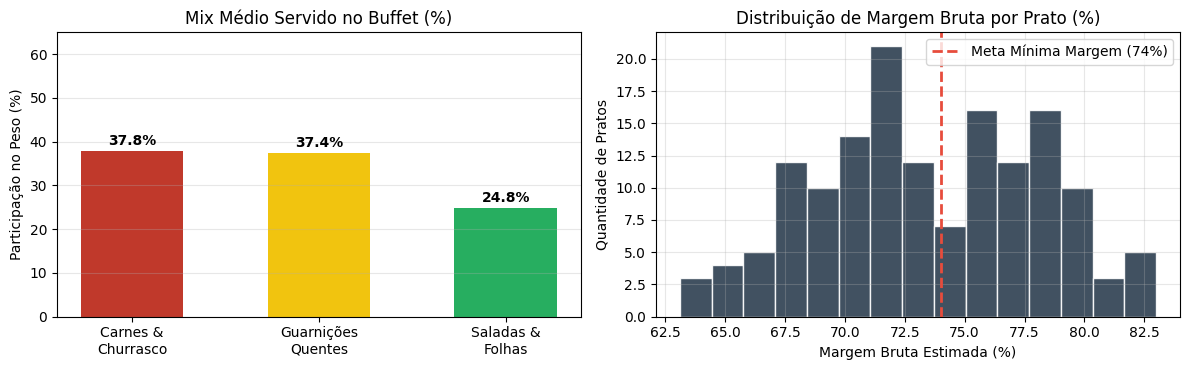

In [8]:
# Simula o registro automático de 150 comandas pesadas no horário de pico da Rua Augusta
rng = np.random.default_rng(2026)
registros_turno = []

for i in range(1, 151):
    hora_min = f"12:{rng.integers(10, 60):02d}" if i <= 95 else f"13:{rng.integers(0, 25):02d}"
    peso_g = int(np.clip(rng.normal(560, 115), 280, 920))

    # Gera uma proporção realista de consumo executivo
    p_carne = float(np.clip(rng.normal(0.38, 0.14), 0.10, 0.78))
    p_salada = float(np.clip(rng.normal(0.24, 0.10), 0.05, 0.55))
    p_guarn = max(0.05, 1.0 - p_carne - p_salada)
    soma = p_carne + p_salada + p_guarn
    p_carne, p_guarn, p_salada = p_carne / soma, p_guarn / soma, p_salada / soma

    peso_kg = peso_g / 1000.0
    receita = peso_kg * PRECO_KG_VENDA
    custo = peso_kg * (
        p_carne * CUSTO_KG_INSUMOS["Carnes & Churrasco"]
        + p_guarn * CUSTO_KG_INSUMOS["Guarnições Quentes"]
        + p_salada * CUSTO_KG_INSUMOS["Saladas & Folhas"]
    )
    registros_turno.append({
        "Comanda": f"{1000 + i:04d}",
        "Horario": hora_min,
        "Peso_g": peso_g,
        "Carnes_pct": round(p_carne * 100, 1),
        "Guarnicoes_pct": round(p_guarn * 100, 1),
        "Saladas_pct": round(p_salada * 100, 1),
        "Receita_RS": round(receita, 2),
        "CMV_RS": round(custo, 2),
        "Margem_pct": round((receita - custo) / receita * 100, 1),
    })

df_turno = pd.DataFrame(registros_turno)

# Exibindo KPIs Consolidados para o Gerente da Loja
faturamento_amostra = df_turno["Receita_RS"].sum()
cmv_medio_pct = (df_turno["CMV_RS"].sum() / faturamento_amostra) * 100
alertas_carne = (df_turno["Carnes_pct"] >= 55.0).sum()

print("📊 RESUMO GERENCIAL — TURNO ALMOÇO (AMOSTRA DE 150 COMANDAS NO PICO)")
print("=" * 68)
print(f"• Ticket Médio (Comida):      R$ {df_turno['Receita_RS'].mean():.2f} (Peso médio: {df_turno['Peso_g'].mean():.0f} g)")
print(f"• Mix Médio do Buffet:        {df_turno['Carnes_pct'].mean():.1f}% Carnes | {df_turno['Guarnicoes_pct'].mean():.1f}% Guarnições | {df_turno['Saladas_pct'].mean():.1f}% Saladas")
print(f"• CMV Real Estimado do Turno: {cmv_medio_pct:.1f}% (Meta da casa: <= 26.0%)")
print(f"• Pratos Críticos (>55% carne): {alertas_carne} comandas ({alertas_carne/len(df_turno):.1%} do fluxo)")
print("=" * 68)

# Gráficos Gerenciais do Turno
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))

# Gráfico 1: Composição média do prato no turno
categorias_mix = ["Carnes &\nChurrasco", "Guarnições\nQuentes", "Saladas &\nFolhas"]
valores_mix = [df_turno["Carnes_pct"].mean(), df_turno["Guarnicoes_pct"].mean(), df_turno["Saladas_pct"].mean()]
cores_mix = ["#C0392B", "#F1C40F", "#27AE60"]

bars = ax1.bar(categorias_mix, valores_mix, color=cores_mix, width=0.55)
ax1.set_title("Mix Médio Servido no Buffet (%)")
ax1.set_ylabel("Participação no Peso (%)")
ax1.set_ylim(0, 65)
ax1.grid(axis="y", alpha=0.3)
for b in bars:
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 1.5, f"{b.get_height():.1f}%", ha="center", fontweight="bold")

# Gráfico 2: Distribuição da Margem Bruta por Prato
ax2.hist(df_turno["Margem_pct"], bins=15, color="#2C3E50", edgecolor="white", alpha=0.9)
ax2.axvline(74.0, color="#E74C3C", linestyle="--", linewidth=2, label="Meta Mínima Margem (74%)")
ax2.set_title("Distribuição de Margem Bruta por Prato (%)")
ax2.set_xlabel("Margem Bruta Estimada (%)")
ax2.set_ylabel("Quantidade de Pratos")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
# Lista todas as imagens disponíveis na pasta 'exemplos_pratos'
arquivos_disponiveis = sorted([
    f for f in os.listdir(PASTA_IMAGENS)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

def painel_balanca_ao_vivo(arquivo_prato=arquivos_disponiveis[0], peso_balanca_g=580):
    caminho = os.path.join(PASTA_IMAGENS, arquivo_prato)
    res = analisar_prato_balanca(caminho, peso_gramas=peso_balanca_g, comanda_id="2048")

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

    # 1. Foto capturada pela câmera zenital
    axes[0].imshow(res["img_original"])
    axes[0].set_title("1. Câmera Zenital (Balança)", fontsize=10, fontweight="bold")
    axes[0].axis("off")

    # 2. Segmentação IA (Raio-X do Prato)
    axes[1].imshow(res["img_raiox"])
    axes[1].set_title("2. Raio-X IA (Segmentação CMV)", fontsize=10, fontweight="bold")
    axes[1].axis("off")

    # 3. Gráfico de barras da composição em gramas
    grupos = ["Carnes\n(Alto CMV)", "Guarnições\n(Médio CMV)", "Saladas\n(Baixo CMV)"]
    gramas = [
        res["pesos_g"]["Carnes & Churrasco"],
        res["pesos_g"]["Guarnições Quentes"],
        res["pesos_g"]["Saladas & Folhas"],
    ]
    cores = ["#D22D2D", "#EBB937", "#2EAF50"]
    barras = axes[2].bar(grupos, gramas, color=cores, width=0.55)
    axes[2].set_title(f"3. Composição Estimada ({peso_balanca_g} g)", fontsize=10, fontweight="bold")
    axes[2].set_ylabel("Peso Estimado (g)")
    axes[2].set_ylim(0, max(peso_balanca_g * 0.85, 100))
    axes[2].grid(axis="y", alpha=0.3)
    for b in barras:
        axes[2].text(b.get_x() + b.get_width()/2, b.get_height() + 10, f"{b.get_height():.0f}g", ha="center", fontsize=9, fontweight="bold")

    plt.tight_layout()
    plt.show()

    print(f"🧾 COMANDA #{res['comanda']} | Peso Total: {res['peso_g']} g | Valor Cobrado: R$ {res['receita_rs']:.2f}")
    print(f"💰 Custo Estimado Insumos (CMV): R$ {res['custo_cmv_rs']:.2f} | Margem Bruta: R$ {res['margem_rs']:.2f} ({res['margem_pct']:.1f}%)")
    print(f"📌 Diagnóstico Operacional: {res['status']}")

print("🖥️ Selecione o prato e ajuste o peso da balança abaixo:")
interact(
    painel_balanca_ao_vivo,
    arquivo_prato=Dropdown(options=arquivos_disponiveis, description="Foto Prato:"),
    peso_balanca_g=IntSlider(min=250, max=950, step=10, value=580, description="Peso (g):")
);

🖥️ Selecione o prato e ajuste o peso da balança abaixo:


interactive(children=(Dropdown(description='Foto Prato:', options=('01_prato_leve_salada.png', '02_prato_execu…